# Aave V4 and Morpho V2: Yield, Costs and Access to Cash

**Does today's quoted yield compensate for the costs and exit constraints?**

This snapshot compares **Aave V4 Core / Main**, two **Morpho Vaults V2** USDC vaults, and **SGOV**, a short-term Treasury ETF. Aave's variable supply APY was **5.45%**. The two Morpho vaults' six-hour realized APYs were **4.53%–4.55%**. SGOV's issuer-reported 30-day SEC yield was **3.74%**.

**Snapshot collected:** 2026-10-16T06:03:32 through 06:03:36 UTC (15 October 2026, 23:03 PDT). **SGOV yield date:** 2026-10-14. These are different rate conventions and observation windows, not matched realized returns.

[Reproduce from the README](../README.md#reproduce) · [Exact data sources and contracts](../docs/DATA_SOURCES.md#current-v4v2-snapshot) · [Snapshot hashes](../data/current_manifest.json) · [Comparison design](../docs/CURRENT_COMPARISON.md).

**Version boundary:** the earlier historical study used Aave **V3** and Morpho **V1**. Its narrowing yield spread and April cash squeeze do not describe today's V4/V2 contracts. That evidence is preserved in the [historical Treasury comparison](03_historical_treasury_comparison.ipynb) and [liquidity appendix](02_liquidity_details.ipynb).

## 1. Rates: similar units, different meanings

- **Aave V4:** the current variable supply APY for native USDC in Main, connected to the Core Hub. It changes with lending conditions; it is not locked for your holding period.
- **Morpho Vaults V2:** annualized growth in vault share price over the last **six hours**, after vault fees and excluding rewards. The **30-day** figures below provide a less short-term reference. V2 is the vault version, not a claim that all underlying lending markets are version 2.
- **SGOV:** the issuer's standardized **30-day SEC income yield**, net of fund expenses. It is neither APY nor a guaranteed forward total return. SGOV is a Treasury ETF proxy, not a directly purchased bill held to maturity.

The two named Morpho curators preserve context from the older study. They were selected by identity, not by the highest current APY. The sample is not representative of all vaults.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'current_analysis.py').exists()
sys.path.insert(0,str(ROOT))
from current_analysis import build, NAMES, ORDER
from current_figures import build as build_figures
rates, scenarios, provenance=build()
figures=build_figures((rates,scenarios,provenance))
quotes=rates[['name','quote_rate','convention','lookback_30d_apy','source_as_of']].set_index('name')
quotes.columns=['Reported rate','Rate convention','Morpho 30-day APY','Quote date / retrieval UTC']
display(quotes.style.format({'Reported rate':'{:.2%}','Morpho 30-day APY':'{:.2%}'},na_rep='—'))

,Reported rate,Rate convention,Morpho 30-day APY,Quote date / retrieval UTC
name,,,,
Aave V4 · Main,5.45%,Variable supply APY,—,2026-10-16T06:03:33.292662+00:00
Morpho V2 · Steakhouse Prime,4.55%,6-hour realized post-fee APY,4.48%,2026-10-16T06:03:34.810994+00:00
Morpho V2 · Gauntlet Prime,4.53%,6-hour realized post-fee APY,4.48%,2026-10-16T06:03:35.595968+00:00
SGOV · Treasury ETF,3.74%,30-day SEC yield (not APY),—,2026-10-14


**Primary sources:** [Aave V4 reserve API documentation](https://www.aave.com/docs/aave-v4/liquidity/reserves) · [Morpho V2 data and realized APY documentation](https://docs.morpho.org/developers/earn/tutorials/get-data/) · [iShares SGOV](https://www.ishares.com/us/products/314116/ishares-0-3-month-treasury-bond-etf). The collector saves exact API queries, responses and retrieval times. Aave's response is not block-pinned; Morpho's indexed blocks are recorded separately for each endpoint. They are not one atomic on-chain snapshot.

## 2. The holding period determines how much yield survives costs

The right panel is a **constant-rate illustration**, not a forecast or backtest. It asks what each quote would imply if it persisted. The DeFi APYs are used directly. For this arithmetic only, the nominal semiannualized SEC yield is converted to an effective annual rate: `(1 + SEC yield / 2)² − 1`. This standardizes compounding without pretending the source measurements have the same window.

**Base assumptions, each side:** DeFi USD 10 fixed plus a 5 bp conversion spread; SGOV 0.5 bp spread and zero broker commission. One basis point is 0.01%. Entry costs reduce the amount invested; exit costs reduce proceeds. USDC is assumed convertible at USD 1. Fund and vault fees are already reflected and are not deducted twice. Rewards, taxes, USDC depegging and SGOV price/NAV changes are excluded.

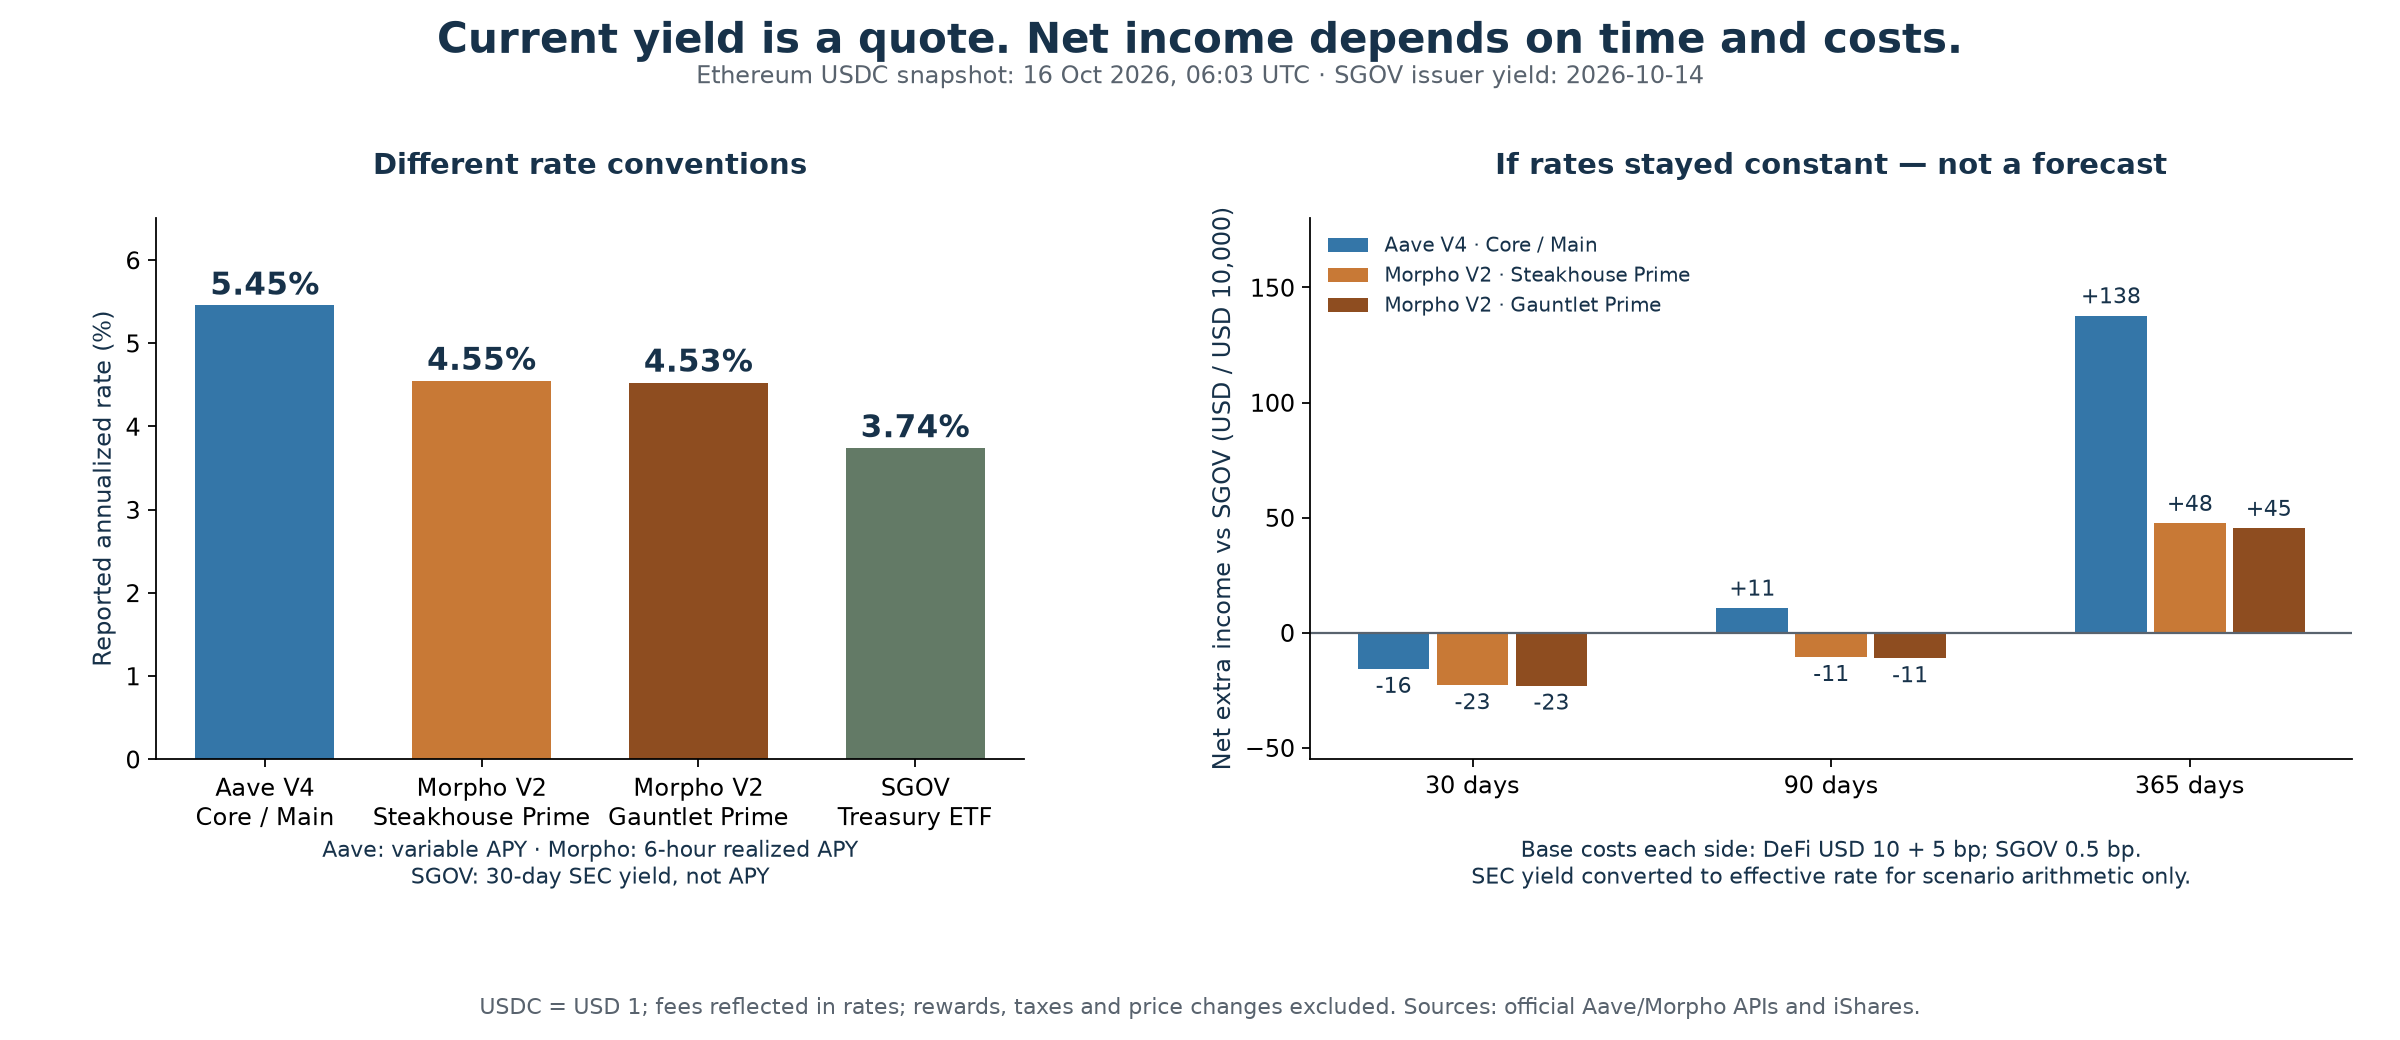

In [2]:
display(Image(filename=str(figures[0]), alt='Current rate quotes with distinct conventions, and 30-, 90- and 365-day net income scenarios versus SGOV.'))

In [3]:
base=scenarios.query("capital==10000 and scenario=='Base'").pivot(index='product',columns='days',values='extra_vs_sgov').reindex(ORDER[:-1])
base.index=base.index.map(NAMES)
base.columns=[f'{d} days' for d in base.columns]
display(Markdown('**Illustrative extra income versus SGOV per USD 10,000, after base costs (USD)**'))
display(base.style.format('{:+,.2f}'))

**Illustrative extra income versus SGOV per USD 10,000, after base costs (USD)**

,30 days,90 days,365 days
product,,,
Aave V4 · Main,-15.84,+10.76,+137.79
Morpho V2 · Steakhouse Prime,-22.93,-10.68,+47.58
Morpho V2 · Gauntlet Prime,-23.10,-11.20,+45.40


The gross rate advantage does not automatically produce a short-horizon gain. Negative entries mean the assumed costs consume the premium; positive entries mean an illustrative advantage **if these rates persist**. This is a statement about the specified arithmetic, not an expected return or a recommendation.

### Cost and deposit-size sensitivity

| Scenario | DeFi fixed cost each side | DeFi spread each side | SGOV spread each side |
|---|---:|---:|---:|
| Low | USD 5 | 0 bp | 0.5 bp |
| Base | USD 10 | 5 bp | 0.5 bp |
| High | USD 50 | 25 bp | 2.5 bp |

These are transparent assumptions, **not current gas estimates or measured executable quotes**. A user who already holds USDC may face different conversion costs. SGOV's reported 30-day median full bid/ask spread was 1 bp as of 2026-10-14; actual trades can differ. Its 0.09% expense ratio is already included in SEC yield.

In [4]:
sensitivity=scenarios.query("days==90 and product!='sgov'").pivot(index=['product','capital'],columns='scenario',values='extra_vs_sgov').reindex(columns=['Low','Base','High'])
sensitivity.index=sensitivity.index.set_levels(sensitivity.index.levels[0].map(NAMES),level=0)
sensitivity.index.names=['Product','Starting capital (USD)']
display(Markdown('**90-day extra income versus SGOV (USD): constant rates, varying costs and capital**'))
display(sensitivity.style.format('{:+,.2f}'))

**90-day extra income versus SGOV (USD): constant rates, varying costs and capital**

[All 108 scenarios and unrounded values](../reports/current_scenarios.csv). Every calculation is independently reconstructed with high-precision arithmetic. **A larger modeled premium is not proof of sufficient compensation for contract, collateral, stablecoin or liquidity risk.**

## 3. Withdrawal liquidity: what could be accessed now?

These figures measure **aggregate reported capacity**, not guaranteed proceeds for an individual wallet.

- **Aave V4:** available USDC belongs to the **Core Hub**, shared across connected Spokes. The denominator below is Hub-wide supply, not only Main deposits. Aave Pro's “capacity filled” display is not the same as utilization or available-cash fraction.
- **Morpho V2:** `withdrawable_assets` is the official API's reported withdrawal capacity for each vault. It can include cash accessible through adapters even when idle vault cash is zero. The two vaults can rely on overlapping underlying liquidity, so their reported capacities **must not be added**. Routing, gates and position constraints can affect an actual exit; force-deallocation or in-kind exits are not assumed to deliver immediate, cost-free USDC.
- **SGOV:** shares sell during exchange hours at the executable bid, with a spread; cash ordinarily settles **T+1**. A Treasury ETF has no directly comparable on-chain cash-buffer fraction. We have not measured its order-book depth or guaranteed a liquidation size.

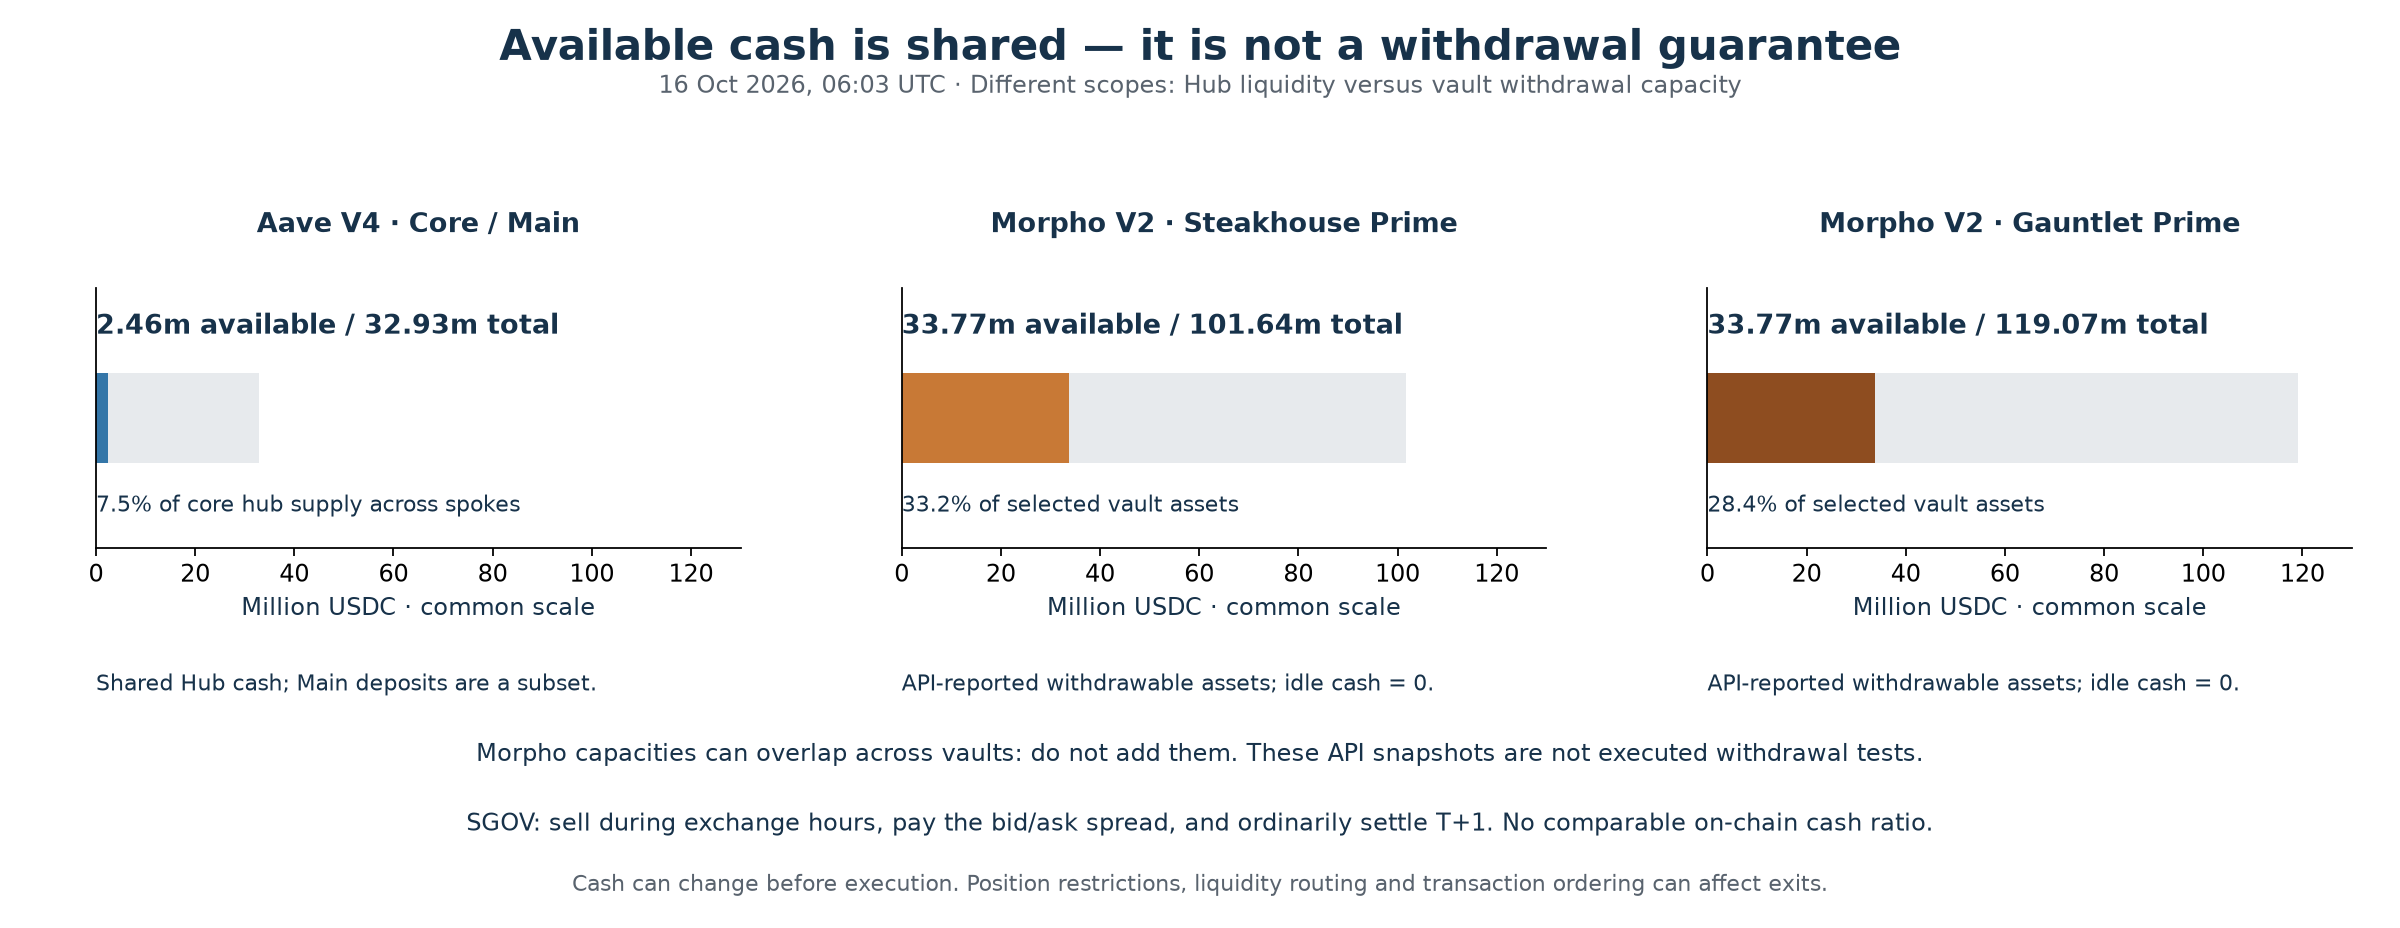

In [5]:
display(Image(filename=str(figures[1]), alt='Aave Core Hub available cash and Morpho V2 API withdrawal capacities, with distinct denominators and shared-liquidity warnings.'))

In [6]:
liquidity=rates.loc[ORDER[:-1],['name','available_usdc','denominator_usdc','cash_fraction','denominator_scope','indexed_block']].set_index('name')
liquidity.columns=['Reported available USDC','Reference total USDC','Fraction','Scope of reference total','Morpho state indexed block']
display(liquidity.style.format({'Reported available USDC':'{:,.0f}','Reference total USDC':'{:,.0f}','Fraction':'{:.1%}','Morpho state indexed block':'{:.0f}'},na_rep='Not provided'))

,Reported available USDC,Reference total USDC,Fraction,Scope of reference total,Morpho state indexed block
name,,,,,
Aave V4 · Main,"2,455,908","32,928,636",7.5%,Core Hub total supply; shared across Spokes,Not provided
Morpho V2 · Steakhouse Prime,"33,765,908","101,635,892",33.2%,Selected vault total assets,26203175
Morpho V2 · Gauntlet Prime,"33,765,908","119,071,400",28.4%,Selected vault total assets,26203175


Aave's Hub had **2.46 million USDC** available against **32.93 million** supplied. Steakhouse reported **33.77 million USDC** withdrawable, and Gauntlet **33.77 million**, against different vault asset totals. These descriptive fractions are **not safety rankings**. This snapshot does not measure how fast cash replenishes, whether everyone can exit together, or realized slippage. A read-only transaction simulation for a specific wallet and amount would be needed to assess execution more closely.

**Mechanism references:** [Aave V4 Hubs](https://www.aave.com/docs/aave-v4/liquidity/hubs) · [Aave withdrawal conditions](https://www.aave.com/docs/aave-v4/positions/withdraw) · [Morpho V2 asset flow](https://docs.morpho.org/developers/earn/tutorials/assets-flow/) · [Morpho force-deallocation](https://docs.morpho.org/developers/earn/tutorials/force-deallocate/) · [SEC T+1 explanation](https://www.investor.gov/introduction-investing/general-resources/news-alerts/alerts-bulletins/investor-bulletins/new-t1-settlement-cycle-what-investors-need-know-investor-bulletin).

## 4. Historical stress is context, not a V4 backtest

The archived **Aave V3 Ethereum Core** observation on **21 April 2026, 00:00 UTC** recorded only **6,519 USDC** available against roughly **2.10 billion USDC of claims**. It followed the documented 18 April Kelp rsETH bridge incident. Aave's contracts were not compromised. The cash minimum was cross-checked with two RPC providers; it is not evidence of realized USDC principal loss or proof that a specific withdrawal failed.

That was a **different contract and architecture**. It illustrates why income accrual and cash access are separate questions; it does **not** establish how V4 or these V2 vaults would behave in the same stress. The original historical yield advantage narrowed over 2024–2026, but those period averages must not replace current product quotes.

[Historical Treasury notebook](03_historical_treasury_comparison.ipynb) · [Liquidity details](02_liquidity_details.ipynb) · [Official incident report](https://governance.aave.com/t/rseth-incident-report-april-20-2026/24580).

## 5. What this comparison supports

**The current rate advantage is real as a quoted comparison; the realized advantage is unknown.** The new products quote higher rates than SGOV's current income measure, but the measures have different windows. Short holding periods and fixed costs can consume the apparent premium.

**Cash access deserves a separate display.** A useful lending interface would show net income for the user's amount and holding period, the exact product version, a dated rate convention, and an amount-specific withdrawal estimate. An APY leaderboard cannot answer all of those questions.

This exploratory snapshot does not estimate default probabilities, optimal allocation, future rates or risk-adjusted superiority. It excludes rewards, taxes and currency/market-price changes. It samples two selected surviving vaults, and API-reported capacity has not been tested by executing transactions. A stronger next study would collect a synchronized V4/V2 time series and compare actual exit quotes through stress.

## Sources and reproducibility

[Watch the captioned 38-second summary](../animations/usdc_lending_linkedin.mp4) · [Video sources and reproduction](../animations/README.md). The video is derived from the checked results above; the April V3 observation is labelled historical context.

- [Exact contracts, URLs and definitions](../docs/DATA_SOURCES.md#current-v4v2-snapshot).
- [Read-only source collector](../collect_current.py), [frozen raw-response hashes](../data/current_manifest.json), [numeric output](../reports/current_rates.csv).
- [Scenario calculations](../current_analysis.py), [verification summary](../reports/current_checks.json), [tests](../test_current.py), [figure code](../current_figures.py).
- [README: reproduce offline or explicitly refresh](../README.md#reproduce). Refreshing creates a new vintage; it is not a replay of this snapshot.

For educational purposes only. Not financial advice.